<a href="https://colab.research.google.com/github/bayuaripermana/bayuaripermana/blob/main/Employee_data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [101]:
import os
print(os.listdir("/content"))

['.config', 'Messy_Employee_dataset.csv', 'sample_data']


In [102]:
import pandas as pd



In [103]:
df = pd.read_csv("/content/Messy_Employee_dataset.csv")
print(df)

     Employee_ID First_Name Last_Name   Age   Department_Region    Status  \
0        EMP1000        Bob     Davis  25.0   DevOps-California    Active   
1        EMP1001        Bob     Brown   NaN       Finance-Texas    Active   
2        EMP1002      Alice     Jones   NaN        Admin-Nevada   Pending   
3        EMP1003        Eva     Davis  25.0        Admin-Nevada  Inactive   
4        EMP1004      Frank  Williams  25.0  Cloud Tech-Florida    Active   
...          ...        ...       ...   ...                 ...       ...   
1015     EMP2015      David    Miller  30.0       HR-California    Active   
1016     EMP2016      David   Johnson  30.0    Cloud Tech-Texas  Inactive   
1017     EMP2017    Charlie  Williams  40.0    Finance-New York    Active   
1018     EMP2018      Alice    Garcia  30.0          HR-Florida  Inactive   
1019     EMP2019      Heidi     Jones  30.0     DevOps-Illinois   Pending   

       Join_Date     Salary                         Email       Phone  \
0 

Memahami struktur dataset (Data Inspection)

In [104]:
print("jumlah baris dan kolom:")
print(df.shape)

print("\nInformasi dataset:")
print(df.info())

print("\nLima data pertama:")
print(df.head())

print("\nLima data terakhir:")
print(df.tail())

print("\nStatistik deskriptif: ")
print(df.describe())

jumlah baris dan kolom:
(1020, 12)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   First_Name         1020 non-null   object 
 2   Last_Name          1020 non-null   object 
 3   Age                809 non-null    float64
 4   Department_Region  1020 non-null   object 
 5   Status             1020 non-null   object 
 6   Join_Date          1020 non-null   object 
 7   Salary             996 non-null    float64
 8   Email              1020 non-null   object 
 9   Phone              1020 non-null   int64  
 10  Performance_Score  1020 non-null   object 
 11  Remote_Work        1020 non-null   bool   
dtypes: bool(1), float64(2), int64(1), object(8)
memory usage: 88.8+ KB
None

Lima data pertama:
  Employee_ID First_Name Last_Name   Age   Department_Region    Statu

In [105]:
print(df.dtypes)

Employee_ID           object
First_Name            object
Last_Name             object
Age                  float64
Department_Region     object
Status                object
Join_Date             object
Salary               float64
Email                 object
Phone                  int64
Performance_Score     object
Remote_Work             bool
dtype: object


In [106]:
df.isna().sum()

,0
Employee_ID,0
First_Name,0
Last_Name,0
Age,211
Department_Region,0
Status,0
Join_Date,0
Salary,24
Email,0
Phone,0


In [107]:
df_clean =df.dropna()

In [108]:
df['Age'] = df['Age'].fillna(
    df['Age'].median()
)

In [109]:
df['Salary'] = df['Salary'].fillna(
    df['Salary'].mean()
)

In [110]:
print(df.duplicated().sum())

0


In [111]:
print(
    df.duplicated(
        subset="Employee_ID"
    ).sum()
)

0


In [112]:
df = df.drop_duplicates()

In [113]:
df = df.drop_duplicates(
    subset="Employee_ID",
    keep="first"
)

In [114]:
df['Join_Date'] = pd.to_datetime(
    df['Join_Date'],
    errors='coerce'
)

In [115]:
print(df["Join_Date"].dtype)

datetime64[ns]


In [116]:
df['Salary'] = pd.to_numeric(
    df['Salary'],
    errors='coerce'
)

In [117]:
df[["Department", "Region"]] = (
    df["Department_Region"]
    .str.split("-", n=1, expand=True)
)

In [118]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistik data:")
print(df.describe())

Missing values:
Employee_ID          0
First_Name           0
Last_Name            0
Age                  0
Department_Region    0
Status               0
Join_Date            0
Salary               0
Email                0
Phone                0
Performance_Score    0
Remote_Work          0
Department           0
Region               0
dtype: int64

Duplicate rows:
0

Data types:
Employee_ID                  object
First_Name                   object
Last_Name                    object
Age                         float64
Department_Region            object
Status                       object
Join_Date            datetime64[ns]
Salary                      float64
Email                        object
Phone                         int64
Performance_Score            object
Remote_Work                    bool
Department                   object
Region                       object
dtype: object

Statistik data:
               Age                      Join_Date         Salary         Phone
cou

BAGIAN 3 — MENGHITUNG DAN MENGOLAH INFORMASI

In [119]:
print("Rata-rata gaji:")
print(df['Salary'].mean())

print("\nGaji tertinggi")
print(df['Salary'].max())

print("\nGaji terndah:")
print(df['Salary'].min())

print('\nMedian Gaji:')
print(df['Salary'].median())

print('\nTital gaji:')
print(df['Salary'].sum())


Rata-rata gaji:
85155.05639558233

Gaji tertinggi
119971.65

Gaji terndah:
50047.32

Median Gaji:
85155.05639558233

Tital gaji:
86858157.52349398


In [120]:
df.describe()

,Age,Join_Date,Salary,Phone
count,1020.000000,1020,1020.000000,1.020000e+03
mean,31.970588,2022-07-26 12:53:38.823529472,85155.056396,-4.942253e+09
min,25.000000,2020-01-01 00:00:00,50047.320000,-9.994973e+09
25%,30.000000,2021-04-12 06:00:00,68811.232500,-7.341992e+09
50%,30.000000,2022-08-09 12:00:00,85155.056396,-4.943997e+09
75%,35.000000,2023-10-31 12:00:00,100372.662500,-2.520391e+09
max,40.000000,2024-12-29 00:00:00,119971.650000,-3.896086e+06
std,5.136901,NaN,19638.295389,2.817326e+09


In [121]:
print(
    df['Status'].value_counts()
)

Status
Pending     356
Active      352
Inactive    312
Name: count, dtype: int64


In [122]:
print(
    df["Status"].value_counts(
        normalize=True
    )
)

Status
Pending     0.349020
Active      0.345098
Inactive    0.305882
Name: proportion, dtype: float64


In [123]:
df["Performance_Score"].value_counts()

,count
Performance_Score,
Good,270
Average,267
Excellent,267
Poor,216


In [124]:
df['Remote_Work'].value_counts()

,count
Remote_Work,
True,513
False,507


In [125]:
df['Department'].value_counts()

,count
Department,
DevOps,189
Sales,178
HR,171
Finance,170
Admin,166
Cloud Tech,146


In [126]:
active_employees = df[
    df['Status'] == 'Active'
]
print('active_employees')

active_employees


In [127]:
high_salary = df[
    df["Salary"] > 80000
]

In [128]:
selected = df[(df["Status"] == "Active") | (df["Salary"] > 80000)]


In [129]:
selected = df[
    (df["Status"] == "Active") |
    (df["Salary"] == "Pending")
]

In [130]:
salary_by_department = (
    df.groupby("Department")["Salary"]
    .mean()
)
print("salary_by_department")

salary_by_department


In [131]:
employee_count = (
    df.groupby("Department")["Employee_ID"].count()
)

print("employee_count")

employee_count


In [132]:
salary_by_status = (
    df.groupby("Status")["Salary"]
    .mean()
)

In [133]:
employee_summary = (
    df.groupby(
        ["Department", "Status"]
    )["Employee_ID"].count()
)

print("employee_summary")

employee_summary


In [134]:
salary_summary = (
    df.groupby("Department")
    ["Salary"].agg(
        ["count","mean","max","min","median","sum"]
    )
)

print(salary_summary)

            count          mean        max       min        median  \
Department                                                           
Admin         166  85190.812361  119574.27  50110.66  86383.915000   
Cloud Tech    146  84930.982137  119971.65  50047.32  85155.056396   
DevOps        189  85993.246730  119586.11  50568.35  85155.056396   
Finance       170  82274.898016  118672.76  50060.73  83809.195000   
HR            171  85466.190851  119890.35  50557.84  85155.056396   
Sales         178  86867.327804  119801.30  50288.67  86453.775000   

                     sum  
Department                
Admin       1.414167e+07  
Cloud Tech  1.239992e+07  
DevOps      1.625272e+07  
Finance     1.398673e+07  
HR          1.461472e+07  
Sales       1.546238e+07  


In [135]:
salary_summary = (
    df.groupby("Department").agg
    (
        total_karyawan=("Employee_ID", "count"),
        rata_rata_gaji=("Salary", "mean"),
        gaji_maksimum=("Salary", "max"),
        gaji_minimum=("Salary", "min")

    )

)

print(salary_summary)

            total_karyawan  rata_rata_gaji  gaji_maksimum  gaji_minimum
Department                                                             
Admin                  166    85190.812361      119574.27      50110.66
Cloud Tech             146    84930.982137      119971.65      50047.32
DevOps                 189    85993.246730      119586.11      50568.35
Finance                170    82274.898016      118672.76      50060.73
HR                     171    85466.190851      119890.35      50557.84
Sales                  178    86867.327804      119801.30      50288.67


In [136]:
df["Full_Name"] = (
    df["First_Name"] + " " + df["Last_Name"]
)

In [137]:
df["Salary_Category"] = df["Salary"].apply(
    lambda x: "High" if x >= 90000 else "Standard"
)

In [138]:
df["Join_Date"] = pd.to_datetime(
    df["Join_Date"],
    errors="coerce"
)

In [139]:
df["Join_Year"] = df["Join_Date"].dt.year

In [140]:
df["Join_Month"] = df["Join_Date"].dt.month

In [141]:
employees_per_year = (
    df.groupby('Join_Year')["Employee_ID"].count()
)

print(employees_per_year)


Join_Year
2020    203
2021    189
2022    183
2023    228
2024    217
Name: Employee_ID, dtype: int64


In [142]:
pivot = pd.pivot_table(
    df,
    index="Department",
    columns="Status",
    values="Employee_ID",
    aggfunc="count"

)

print(pivot)

Status      Active  Inactive  Pending
Department                           
Admin           58        51       57
Cloud Tech      45        42       59
DevOps          78        58       53
Finance         49        62       59
HR              57        49       65
Sales           65        50       63


In [143]:
employee_data = pd.DataFrame({
    "Employee_ID" : ["E001", "E002", "E003"],
    "Name" : ["John", "Jane", "Bob"],
})

department_data = pd.DataFrame({
    "Employee_ID" : ["E001", "E002", "E003"],
    "Department" : ["HR", "IT", "Finance"]
})

merged_data = pd.merge(
    employee_data,
    department_data,
    on="Employee_ID",
    how="inner"
)

print(merged_data)

  Employee_ID  Name Department
0        E001  John         HR
1        E002  Jane         IT
2        E003   Bob    Finance


In [144]:
import numpy as np

# 1. Cetak variabel, bukan teks
print(salary_by_department)

# 2. Filter yang benar
selected = df[(df["Status"] == "Active") | (df["Salary"] > 80000)]

# 3. Phone sebagai string, lalu tandai yang tidak valid
df["Phone"] = df["Phone"].astype(str)
print("Phone tidak valid:", df["Phone"].str.startswith("-").sum())

# 4. Catat baris yang diimputasi (jalankan SEBELUM fillna)
df["Age_Imputed"] = df["Age"].isna()

# 6. Cara vectorized
df["Salary_Category"] = np.where(df["Salary"] >= 90000, "High", "Standard")

Department
Admin         85190.812361
Cloud Tech    84930.982137
DevOps        85993.246730
Finance       82274.898016
HR            85466.190851
Sales         86867.327804
Name: Salary, dtype: float64
Phone tidak valid: 1020


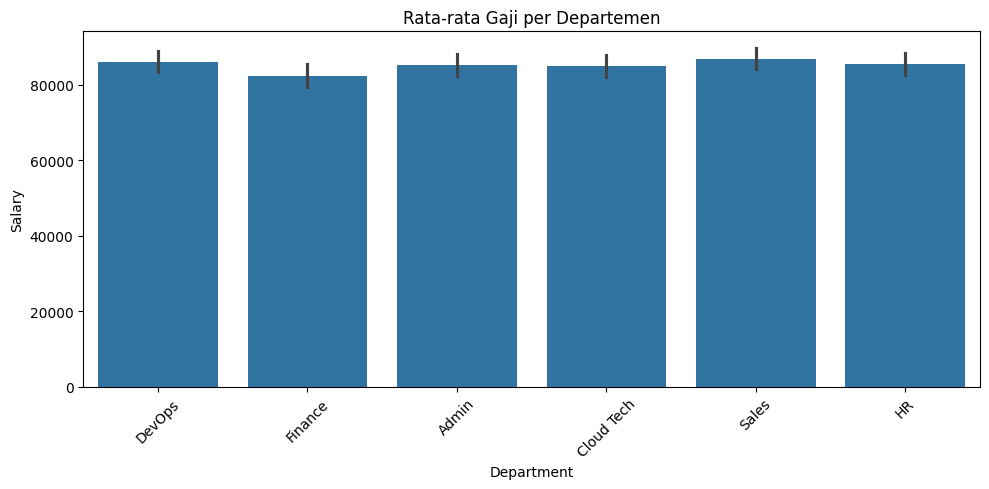

In [145]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Department", y="Salary", estimator="mean")
plt.xticks(rotation=45)
plt.title("Rata-rata Gaji per Departemen")
plt.tight_layout()
plt.show()

In [146]:
# 1. Simpan DataFrame bersih ke CSV
df.to_csv(
    "employee_clean.csv",
    index=False,                # jangan simpan nomor index
    encoding="utf-8-sig",       # terbaca benar di Excel
    date_format="%Y-%m-%d"      # format tanggal standar
)

# 2. Cek bahwa file benar-benar jadi
import os
print("File tersimpan:", os.path.exists("employee_clean.csv"))
print("Ukuran file   :", os.path.getsize("employee_clean.csv"), "bytes")

# 3. Baca ulang untuk memastikan isinya benar
cek = pd.read_csv("employee_clean.csv")
print(cek.shape)
print(cek.head())

File tersimpan: True
Ukuran file   : 169802 bytes
(1020, 19)
  Employee_ID First_Name Last_Name   Age   Department_Region    Status  \
0     EMP1000        Bob     Davis  25.0   DevOps-California    Active   
1     EMP1001        Bob     Brown  30.0       Finance-Texas    Active   
2     EMP1002      Alice     Jones  30.0        Admin-Nevada   Pending   
3     EMP1003        Eva     Davis  25.0        Admin-Nevada  Inactive   
4     EMP1004      Frank  Williams  25.0  Cloud Tech-Florida    Active   

    Join_Date     Salary                       Email       Phone  \
0  2021-04-02   59767.65       bob.davis@example.com -1651623197   
1  2020-07-10   65304.66       bob.brown@example.com -1898471390   
2  2023-12-07   88145.90     alice.jones@example.com -5596363211   
3  2021-11-27   69450.99       eva.davis@example.com -3476490784   
4  2022-01-05  109324.61  frank.williams@example.com -1586734256   

  Performance_Score  Remote_Work  Department      Region       Full_Name  \
0        

In [147]:
from google.colab import files
files.download("employee_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>